<a href="https://colab.research.google.com/github/Devaji-Rashmika/Deep_Learning/blob/main/skill7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
!pip install torch torchvision onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 30.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 105.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [onnx]


In [14]:
import torch
import torch.nn as nn
import tensorrt as trt
import onnx
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [15]:
class SimpleModel(nn.Module):
    def __init__(self):
        super(SimpleModel, self).__init__()

        self.fc1 = nn.Linear(10, 64)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 2)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)

model = SimpleModel()

print(model)

SimpleModel(
  (fc1): Linear(in_features=10, out_features=64, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=2, bias=True)
)


In [19]:
import torch.optim as optim

# Generate sample training data
X = torch.randn(1000, 10)
y = torch.randint(0, 2, (1000,))

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train the model
for epoch in range(10):
    optimizer.zero_grad()

    outputs = model(X)
    loss = criterion(outputs, y)

    loss.backward()
    optimizer.step()

    print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")

print("Training completed successfully!")

Epoch 1, Loss: 0.6991
Epoch 2, Loss: 0.6973
Epoch 3, Loss: 0.6958
Epoch 4, Loss: 0.6947
Epoch 5, Loss: 0.6938
Epoch 6, Loss: 0.6931
Epoch 7, Loss: 0.6925
Epoch 8, Loss: 0.6919
Epoch 9, Loss: 0.6913
Epoch 10, Loss: 0.6907
Training completed successfully!


In [21]:
torch.save({
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict()
}, 'model.pth')

print("Trained checkpoint saved successfully!")

Trained checkpoint saved successfully!


In [22]:
import os

print("Checkpoint exists:", os.path.exists("model.pth"))

Checkpoint exists: True


In [23]:
checkpoint = torch.load(
    "model.pth",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Trained checkpoint loaded successfully!")

Trained checkpoint loaded successfully!


In [24]:
dummy_input = torch.randn(1, 10)

torch.onnx.export(
    model,
    dummy_input,
    "model.onnx",
    input_names=["input"],
    output_names=["output"],
    opset_version=17,
    dynamo=False
)

print("ONNX model generated successfully!")

ONNX model generated successfully!


/tmp/ipykernel_431/462478755.py:3: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [25]:
onnx_model = onnx.load("model.onnx")

onnx.checker.check_model(onnx_model)

print("ONNX validation successful!")

ONNX validation successful!


In [26]:
logger = trt.Logger(trt.Logger.WARNING)

builder = trt.Builder(logger)

network = builder.create_network(0)

parser = trt.OnnxParser(network, logger)

print("TensorRT builder created successfully!")

TensorRT builder created successfully!


In [27]:
with open("model.onnx", "rb") as f:
    if not parser.parse(f.read()):
        for i in range(parser.num_errors):
            print(parser.get_error(i))
        raise RuntimeError("ONNX parsing failed!")

print("ONNX model parsed successfully!")

ONNX model parsed successfully!


In [31]:
# Configure TensorRT
config = builder.create_builder_config()

# Set workspace memory to 1 GB
config.set_memory_pool_limit(
    trt.MemoryPoolType.WORKSPACE,
    1 << 30
)

print("TensorRT configuration completed successfully!")

TensorRT configuration completed successfully!


In [32]:
serialized_engine = builder.build_serialized_network(
    network,
    config
)

if serialized_engine is None:
    raise RuntimeError("TensorRT engine building failed!")

print("TensorRT engine built successfully!")

TensorRT engine built successfully!


In [33]:
with open("model.engine", "wb") as f:
    f.write(serialized_engine)

print("TensorRT Engine saved successfully!")

TensorRT Engine saved successfully!


In [34]:
import os

files = [
    "model.pth",
    "model.onnx",
    "model.engine"
]

for file in files:
    if os.path.exists(file):
        print("SUCCESS:", file, "-", os.path.getsize(file), "bytes")
    else:
        print("MISSING:", file)

SUCCESS: model.pth - 40927 bytes
SUCCESS: model.onnx - 12112 bytes
SUCCESS: model.engine - 35732 bytes


In [35]:
import tensorrt as trt

logger = trt.Logger(trt.Logger.WARNING)
runtime = trt.Runtime(logger)

with open("model.engine", "rb") as f:
    engine = runtime.deserialize_cuda_engine(f.read())

if engine is None:
    raise RuntimeError("Engine loading failed!")

print("TensorRT Engine loaded successfully!")

TensorRT Engine loaded successfully!


In [36]:
print("Number of I/O tensors:", engine.num_io_tensors)

for i in range(engine.num_io_tensors):
    name = engine.get_tensor_name(i)
    print("Tensor:", name)
    print("Shape:", engine.get_tensor_shape(name))
    print("Data Type:", engine.get_tensor_dtype(name))

Number of I/O tensors: 2
Tensor: input
Shape: (1, 10)
Data Type: DataType.FLOAT
Tensor: output
Shape: (1, 2)
Data Type: DataType.FLOAT


In [37]:
import os

print("MODEL ARTEFACT LIFECYCLE SUMMARY")

for file in ["model.pth", "model.onnx", "model.engine"]:
    print(file, ":", "Available" if os.path.exists(file) else "Missing")

print("Architecture: SimpleModel")
print("Checkpoint: Saved")
print("ONNX: Exported and validated")
print("TensorRT: Engine built and saved")

MODEL ARTEFACT LIFECYCLE SUMMARY
model.pth : Available
model.onnx : Available
model.engine : Available
Architecture: SimpleModel
Checkpoint: Saved
ONNX: Exported and validated
TensorRT: Engine built and saved


In [38]:
from google.colab import files

files.download("model.pth")
files.download("model.onnx")
files.download("model.engine")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
print("MODEL ARTEFACT LIFECYCLE COMPLETED")
print("-----------------------------------")
print("1. Model Architecture - Created")
print("2. Trained Checkpoint - Saved")
print("3. ONNX Graph - Exported")
print("4. TensorRT Engine - Built")
print("5. TensorRT Runtime - Loaded")
print("-----------------------------------")
print("Experiment completed successfully!")

MODEL ARTEFACT LIFECYCLE COMPLETED
-----------------------------------
1. Model Architecture - Created
2. Trained Checkpoint - Saved
3. ONNX Graph - Exported
4. TensorRT Engine - Built
5. TensorRT Runtime - Loaded
-----------------------------------
Experiment completed successfully!


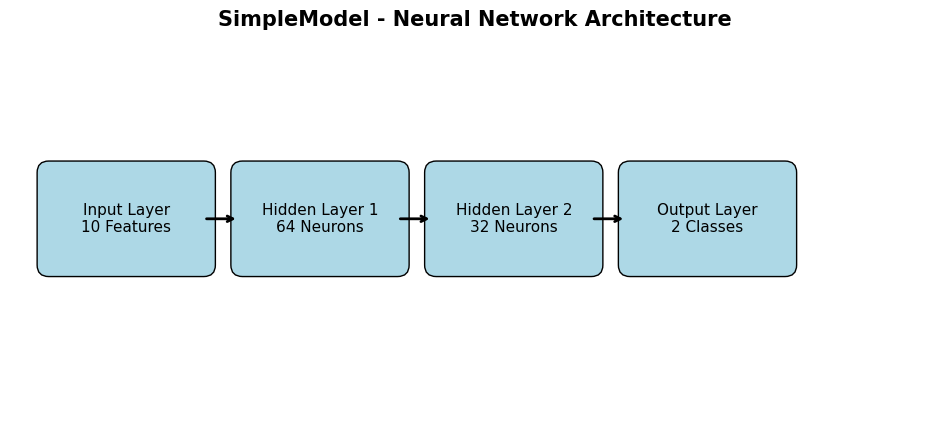

In [40]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 5)
ax.axis("off")

layers = [
    (0.5, "Input Layer\n10 Features"),
    (3.0, "Hidden Layer 1\n64 Neurons"),
    (5.5, "Hidden Layer 2\n32 Neurons"),
    (8.0, "Output Layer\n2 Classes")
]

for x, label in layers:
    box = FancyBboxPatch(
        (x, 2), 2, 1.2,
        boxstyle="round,pad=0.15",
        edgecolor="black",
        facecolor="lightblue"
    )
    ax.add_patch(box)
    ax.text(x + 1, 2.6, label,
            ha="center", va="center", fontsize=11)

for x in [2.5, 5.0, 7.5]:
    ax.annotate(
        "", xy=(x + 0.45, 2.6), xytext=(x, 2.6),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

ax.set_title("SimpleModel - Neural Network Architecture",
             fontsize=15, fontweight="bold")

plt.show()

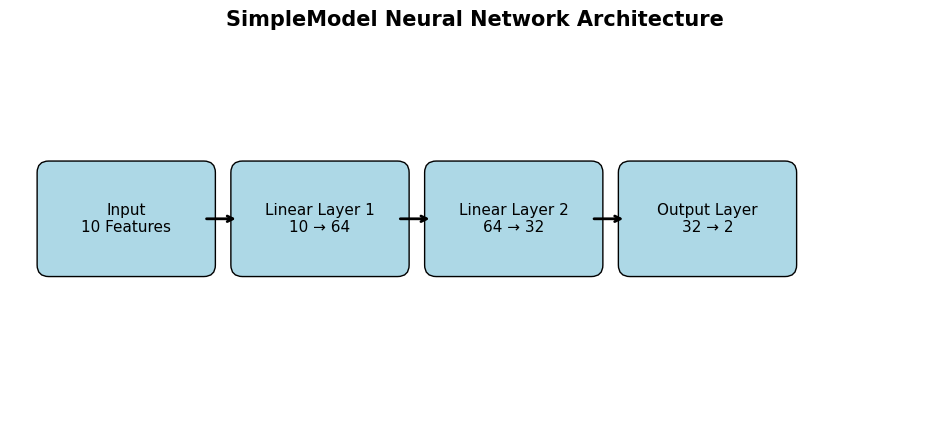

In [41]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 5)
ax.axis("off")

layers = [
    (0.5, "Input\n10 Features"),
    (3.0, "Linear Layer 1\n10 → 64"),
    (5.5, "Linear Layer 2\n64 → 32"),
    (8.0, "Output Layer\n32 → 2")
]

for x, label in layers:
    box = FancyBboxPatch(
        (x, 2), 2, 1.2,
        boxstyle="round,pad=0.15",
        edgecolor="black",
        facecolor="lightblue"
    )
    ax.add_patch(box)
    ax.text(x + 1, 2.6, label, ha="center", va="center", fontsize=11)

for x in [2.5, 5.0, 7.5]:
    ax.annotate("", xy=(x + 0.45, 2.6), xytext=(x, 2.6),
                arrowprops=dict(arrowstyle="->", lw=2))

ax.set_title("SimpleModel Neural Network Architecture",
             fontsize=15, fontweight="bold")

plt.show()

In [42]:
!pip install netron

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 20.6 MB/s  0:00:00


In [45]:
import netron

netron.start("model.onnx", browse=False)

('localhost', 8081)

In [47]:
!apt-get install -y graphviz
!pip install pydot

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


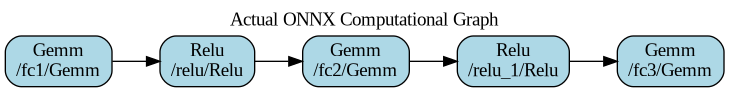

In [48]:
import onnx
import pydot
from IPython.display import Image, display

model = onnx.load("model.onnx")

graph = pydot.Dot(
    graph_type="digraph",
    rankdir="LR",
    label="Actual ONNX Computational Graph",
    labelloc="t"
)

for node in model.graph.node:
    node_label = node.op_type + "\n" + node.name
    graph.add_node(
        pydot.Node(
            node.name if node.name else node.output[0],
            label=node_label,
            shape="box",
            style="rounded,filled",
            fillcolor="lightblue"
        )
    )

for node in model.graph.node:
    for input_name in node.input:
        for previous_node in model.graph.node:
            if input_name in previous_node.output:
                source = previous_node.name if previous_node.name else previous_node.output[0]
                destination = node.name if node.name else node.output[0]
                graph.add_edge(pydot.Edge(source, destination))

display(Image(graph.create_png()))

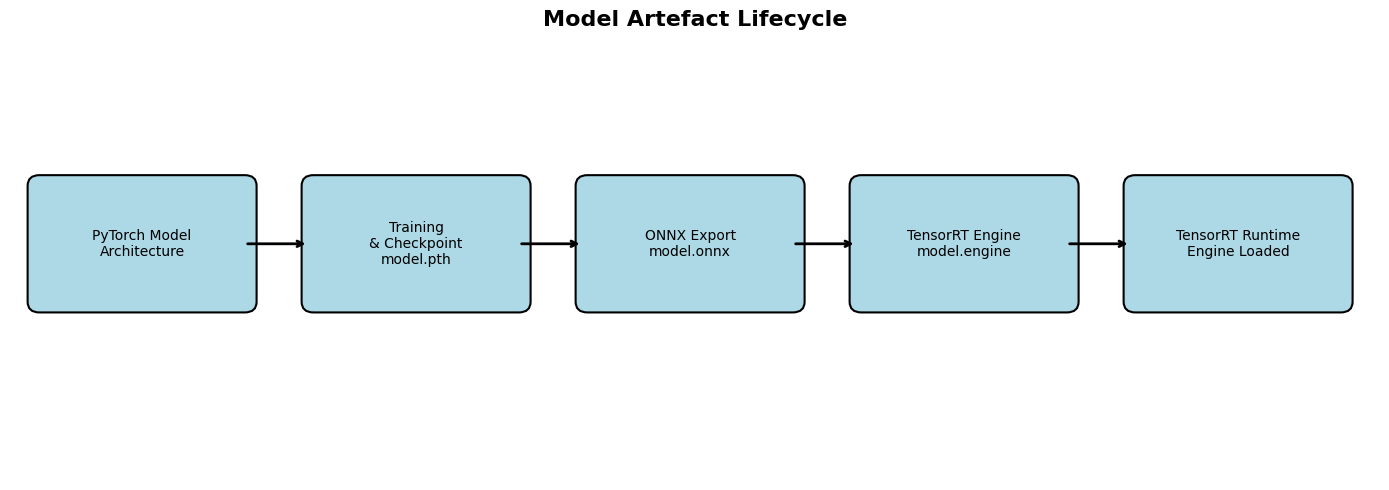

In [49]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 5))
ax.set_xlim(0, 14)
ax.set_ylim(0, 5)
ax.axis("off")

steps = [
    (0.3, "PyTorch Model\nArchitecture"),
    (3.1, "Training\n& Checkpoint\nmodel.pth"),
    (5.9, "ONNX Export\nmodel.onnx"),
    (8.7, "TensorRT Engine\nmodel.engine"),
    (11.5, "TensorRT Runtime\nEngine Loaded")
]

for x, label in steps:
    box = FancyBboxPatch(
        (x, 2), 2.1, 1.3,
        boxstyle="round,pad=0.12",
        edgecolor="black",
        facecolor="lightblue",
        linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(x + 1.05, 2.65, label,
            ha="center", va="center", fontsize=10)

for x in [2.4, 5.2, 8.0, 10.8]:
    ax.annotate(
        "",
        xy=(x + 0.65, 2.65),
        xytext=(x, 2.65),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

ax.set_title(
    "Model Artefact Lifecycle",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

model.pth : 39.97 KB
model.onnx : 11.83 KB
model.engine : 34.89 KB


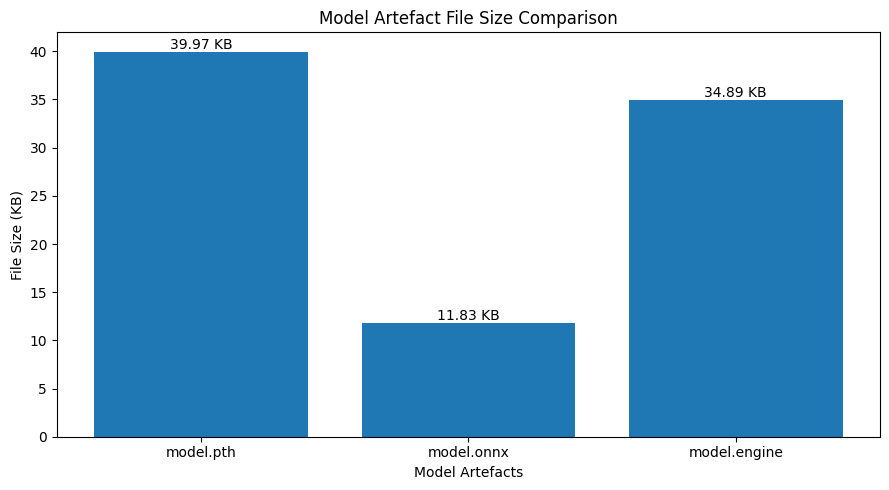

In [50]:
import os
import matplotlib.pyplot as plt

files = ["model.pth", "model.onnx", "model.engine"]

file_names = []
file_sizes = []

for file in files:
    if os.path.exists(file):
        file_names.append(file)
        size_kb = os.path.getsize(file) / 1024
        file_sizes.append(size_kb)
        print(file, ":", round(size_kb, 2), "KB")
    else:
        print(file, "not found!")

plt.figure(figsize=(9, 5))

plt.bar(file_names, file_sizes)

plt.title("Model Artefact File Size Comparison")
plt.xlabel("Model Artefacts")
plt.ylabel("File Size (KB)")

for i, size in enumerate(file_sizes):
    plt.text(i, size, f"{size:.2f} KB", ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [51]:
print("Checking training loss data...")

if "losses" in globals():
    print("Training loss data found!")
    print(losses)
else:
    print("Training loss data was not saved.")

Checking training loss data...
Training loss data was not saved.


In [52]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Create a fresh copy of the same architecture
class LossModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(10, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 2)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

# Generate synthetic training data
torch.manual_seed(42)
X_loss = torch.randn(1000, 10)
y_loss = torch.randint(0, 2, (1000,))

# Initialize model and training components
loss_model = LossModel()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(loss_model.parameters(), lr=0.001)

losses = []

# Train for 10 epochs and record loss
for epoch in range(10):
    optimizer.zero_grad()
    outputs = loss_model(X_loss)
    loss = criterion(outputs, y_loss)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    print(f"Epoch {epoch + 1}/10 - Loss: {loss.item():.4f}")

print("Training loss recording completed!")

Epoch 1/10 - Loss: 0.6936
Epoch 2/10 - Loss: 0.6923
Epoch 3/10 - Loss: 0.6913
Epoch 4/10 - Loss: 0.6904
Epoch 5/10 - Loss: 0.6897
Epoch 6/10 - Loss: 0.6890
Epoch 7/10 - Loss: 0.6883
Epoch 8/10 - Loss: 0.6877
Epoch 9/10 - Loss: 0.6871
Epoch 10/10 - Loss: 0.6864
Training loss recording completed!


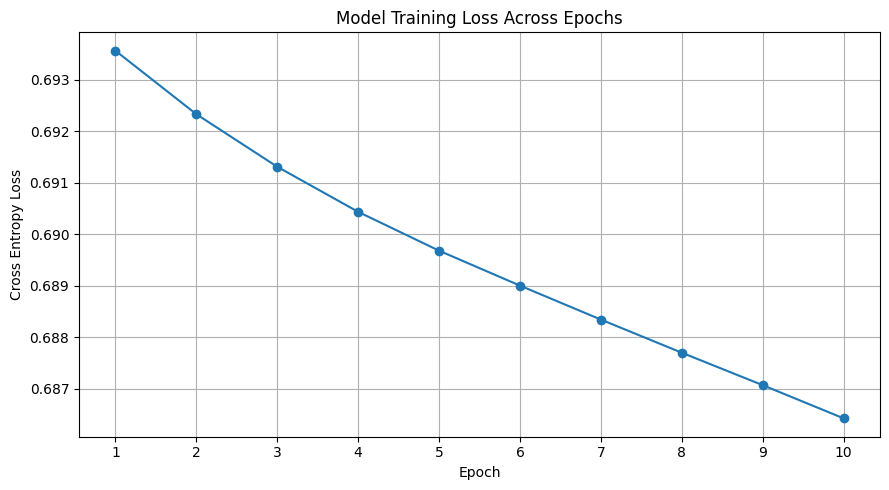

In [53]:
plt.figure(figsize=(9, 5))

plt.plot(range(1, 11), losses, marker="o")

plt.title("Model Training Loss Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.xticks(range(1, 11))
plt.grid(True)

plt.tight_layout()
plt.show()

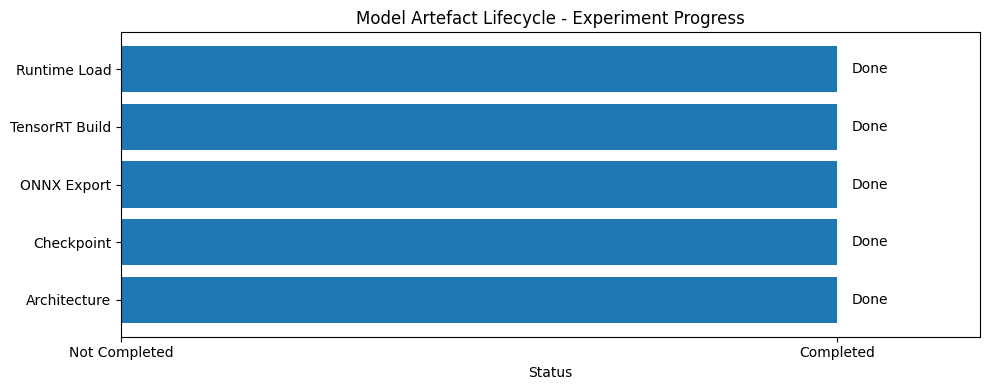

In [54]:
import matplotlib.pyplot as plt

stages = [
    "Architecture",
    "Checkpoint",
    "ONNX Export",
    "TensorRT Build",
    "Runtime Load"
]

completed = [1, 1, 1, 1, 1]

plt.figure(figsize=(10, 4))

plt.barh(stages, completed)

plt.xlim(0, 1.2)
plt.xticks([0, 1], ["Not Completed", "Completed"])
plt.title("Model Artefact Lifecycle - Experiment Progress")
plt.xlabel("Status")

for i in range(len(stages)):
    plt.text(1.02, i, "Done", va="center")

plt.tight_layout()
plt.show()

In [55]:
import os
import onnx
import torch

print("FINAL MODEL ARTEFACT VERIFICATION")
print("----------------------------------")

# Check PyTorch checkpoint
checkpoint = torch.load("model.pth", map_location="cpu")
print("PyTorch Checkpoint:", "SUCCESS" if checkpoint else "FAILED")

# Check ONNX model
onnx_model = onnx.load("model.onnx")
onnx.checker.check_model(onnx_model)
print("ONNX Model:", "SUCCESS")

# Check TensorRT engine file
engine_exists = os.path.exists("model.engine")
print("TensorRT Engine File:", "SUCCESS" if engine_exists else "FAILED")

print("----------------------------------")
print("Verification completed!")

FINAL MODEL ARTEFACT VERIFICATION
----------------------------------
PyTorch Checkpoint: SUCCESS
ONNX Model: SUCCESS
TensorRT Engine File: SUCCESS
----------------------------------
Verification completed!
